# Objectif 

Illustration du dataset portion5_event_ais 

Date de création : 16/11/2026

In [2]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from datetime import datetime

In [3]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *

# Chargement des données 

In [4]:
portion_id = 5

## Données de la portion pour la librairie 
Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. 

In [5]:
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = xr.open_datatree(fpath, auto_complex=True)
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  /home/program/ubf_tools/real_data_analysis/acouplane/d...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2323, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 19kB ...
│   │           atl_lat                 (atl_datetime) float64 19kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               5
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   │           obs_position:             OBS position corrected using LMS inversion.
│   │           obs_position_filepath:    C:\Users\baptiste.menetrier\Desktop\devPy\phd\r...
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2671, mmsi: 526,
│   │                                    ais_datetime: 301, src_datetime: 937)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 21kB 2026-02-25T11:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:0...
│   │         * src_datetime            (src_datetime) datetime64[ns] 7kB 2026-02-25T11:0...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 21kB ...
│   │           atl_lat                 (atl_datetime) float64 21kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 7kB ...
│   │           tir_vessel_lon          (src_datetime) float64 7kB ...
│   │           tir_vessel_lat          (src_datetime) float64 7kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 52kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 52kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 52kB ...
│   │       Attributes:
│   │           description:              Posi

## Données de la portion event
Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. 

In [6]:
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event_ais.nc"
portion_event = xr.open_datatree(fpath, auto_complex=True)
portion_event

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 39)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 312B ...
│   Attributes:
│       box_lon_min:       5.921525852249999
│       box_lon_max:       5.962816177675
│       box_lat_min:       42.986809747449996
│       box_lat_max:       43.060361284900004
│       portion_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_dat...
├── Group: /position
│   ├── Group: /position/event_0
│   │       Dimensions:         (datetime: 12)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 96B 2026-02-27T09:04:30 ... 202...
│   │       Data variables:
│   │           lon             (datetime) float64 96B ...
│   │           lat             (datetime) float64 96B ...
│   │           start_datetime  datetime64[ns] 8B ...
│   │           stop_datetime   datetime64[ns] 8B ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 0
│   │           MMSI:                     1
│   ├── Group: /position/event_1
│   │       Dimensions:         (datetime: 204)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 2kB 2026-02-27T16:13:30 ... 202...
│   │       Data variables:
│   │           lon             (datetime) float64 2kB ...
│   │           lat             (datetime) float64 2kB ...
│   │           start_datetime  datetime64[ns] 8B ...
│   │           stop_datetime   datetime64[ns] 8B ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 1
│   │           MMSI:                     6
│   ├── Group: /position/event_2
│   │       Dimensions:         (datetime: 148)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 1kB 2026-02-24T16:10:40 ... 202...
│   │       Data variables:
│   │           lon             (datetime) float64 1kB ...
│   │           lat             (datetime) float64 1kB ...
│   │           start_datetime  datetime64[ns] 8B ...
│   │           stop_datetime   datetime64[ns] 8B ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 2
│   │           MMSI:                     7
│   ├── Group: /position/event_3
│   │       Dimensions:         (datetime: 58)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 464B 2026-02-27T09:33:20 ... 20...
│   │       Data variables:
│   │           lon             (datetime) float64 464B ...
│   │           lat             (datetime) float64 464B ...
│   │           start_datetime  datetime64[ns] 8B ...
│   │           stop_datetime   datetime64[ns] 8B ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 3
│   │           MMSI:                     9
│   ├── Group: /position/event_4
│   │       Dimensions:         (datetime: 99)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 792B 2026-02-28T05:58:00 ... 20...
│   │       Data variables:
│   │           lon             (datetime) float64 792B ...
│   │           lat             (datetime) float64 792B ...
│   │           start_datetime  datetime64[ns] 8B ...
│   │           stop_da

## Données de positions 
Toutes les données disponibles : 

* Données AIS 
* Données de l'ATALANTE 

In [7]:
ds_pos = xr.open_dataset(ACOUPLANE_POSITIONS_NC_FPATH)
print(ds_pos)

<xarray.Dataset> Size: 520MB
Dimensions:         (rcv_id: 7, atl_datetime: 563739, mmsi: 521,
                     ais_datetime: 60447, src_datetime: 33608)
Coordinates:
  * rcv_id          (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
  * atl_datetime    (atl_datetime) datetime64[ns] 5MB 2026-02-24 ... 2026-03-...
  * ais_datetime    (ais_datetime) datetime64[ns] 484kB 2026-02-23T23:59:50 ....
  * src_datetime    (src_datetime) datetime64[ns] 269kB 2026-02-24T20:14:06.6...
Dimensions without coordinates: mmsi
Data variables: (12/13)
    rcv_lon         (rcv_id) float64 56B ...
    rcv_lat         (rcv_id) float64 56B ...
    rcv_immersion   (rcv_id) int16 14B ...
    atl_lon         (atl_datetime) float64 5MB ...
    atl_lat         (atl_datetime) float64 5MB ...
    ais_lon         (mmsi, ais_datetime) float64 252MB ...
    ...              ...
    tir_SEGD        (src_datetime) int64 269kB ...
    tir_ECOS        (src_datetime) int64 269kB ...
    tir_src_lon     (src_date

# Illustration du dataset 

## Position des trajectoires 

In [8]:
root_img = os.path.join(
    ROOT_ACOUPLANE_PROCESSED_IMG_DIR,
    f"portion{portion_id}",
    "results_event_ais",
)
root_img_selection = os.path.join(
    root_img,
    "ais_selection"
    )
root_img_spectro = os.path.join(root_img_selection, "spectro")
root_img_signal = os.path.join(root_img_selection, "signal")
root_img_position = os.path.join(root_img_selection, "position")

In [10]:
# Plot
batch_size = 5
batch_start = 0
batch_id = 0
while batch_start <= portion_event.event_id.max():

    # portion_event_batch = portion_event.isel(event_id=slice(max(0, last_event_i-batch_size), last_event_i))
    # last_event_i += batch_size
    # print(portion_event_batch)

    event_in_batch = [f"event_{i}" for i in range(batch_start, batch_start+batch_size)]
    batch_start += batch_size
    print(event_in_batch)

    fig, ax = plot_portion_tir_pos(portion_tree=portion)
    ax.add_patch(
        Rectangle(
            (portion_event.box_lon_min, portion_event.box_lat_min),
            portion_event.box_lon_max - portion_event.box_lon_min,
            portion_event.box_lat_max - portion_event.box_lat_min,
            fc="none",
            ec="k",
            lw=5,
            label="Selected area",
        )
    )

    for name, node in portion_event.position.children.items():

        if name not in event_in_batch:
            continue 

        ds_position_section = node.to_dataset()
        plt.plot(
            ds_position_section.lon,
            ds_position_section.lat,
            "-x",
            markersize=2,
            label=f"Event {ds_position_section.event_id}",
        )

    ax.legend()
    legend = ax.get_legend()

    if legend is not None:
        handles = legend.legend_handles
        labels = [text.get_text() for text in legend.get_texts()]

        legend.remove()

        ax.legend(
            handles,
            labels,
            loc="upper right",
            fontsize=16,
            ncols=2,
        )

    fpath = os.path.join(root_img_position, f"event_ais_position_batch{batch_id}.png")
    fig.savefig(fpath)
    plt.close(fig)

    batch_id += 1

['event_0', 'event_1', 'event_2', 'event_3', 'event_4']
['event_5', 'event_6', 'event_7', 'event_8', 'event_9']
['event_10', 'event_11', 'event_12', 'event_13', 'event_14']
['event_15', 'event_16', 'event_17', 'event_18', 'event_19']
['event_20', 'event_21', 'event_22', 'event_23', 'event_24']
['event_25', 'event_26', 'event_27', 'event_28', 'event_29']
['event_30', 'event_31', 'event_32', 'event_33', 'event_34']
['event_35', 'event_36', 'event_37', 'event_38', 'event_39']


## Couverture temporelle 

In [11]:
event_days = np.concat([
    pd.DatetimeIndex(node.datetime).day
    for name, node in portion_event.position.children.items()
])
event_days, unique_idx = np.unique(event_days, return_index=True)
event_days 

event_months = np.concat(
    [
        pd.DatetimeIndex(node.datetime).month
        for name, node in portion_event.position.children.items()
    ]
)
event_months = event_months[unique_idx]
event_months
event_years = np.concat(
    [
        pd.DatetimeIndex(node.datetime).year
        for name, node in portion_event.position.children.items()
    ]
)
event_years = event_years[unique_idx]

dt_bounds = np.asarray(
    [
        np.datetime64(
            datetime(year=event_years[i], month=event_months[i], day=event_days[i])
        )
        for i in range(event_days.size)
    ]
)
dt_bounds = np.sort(dt_bounds)
dt_bounds

array(['2026-02-24T00:00:00.000000', '2026-02-25T00:00:00.000000',
       '2026-02-27T00:00:00.000000', '2026-02-28T00:00:00.000000',
       '2026-03-01T00:00:00.000000'], dtype='datetime64[us]')

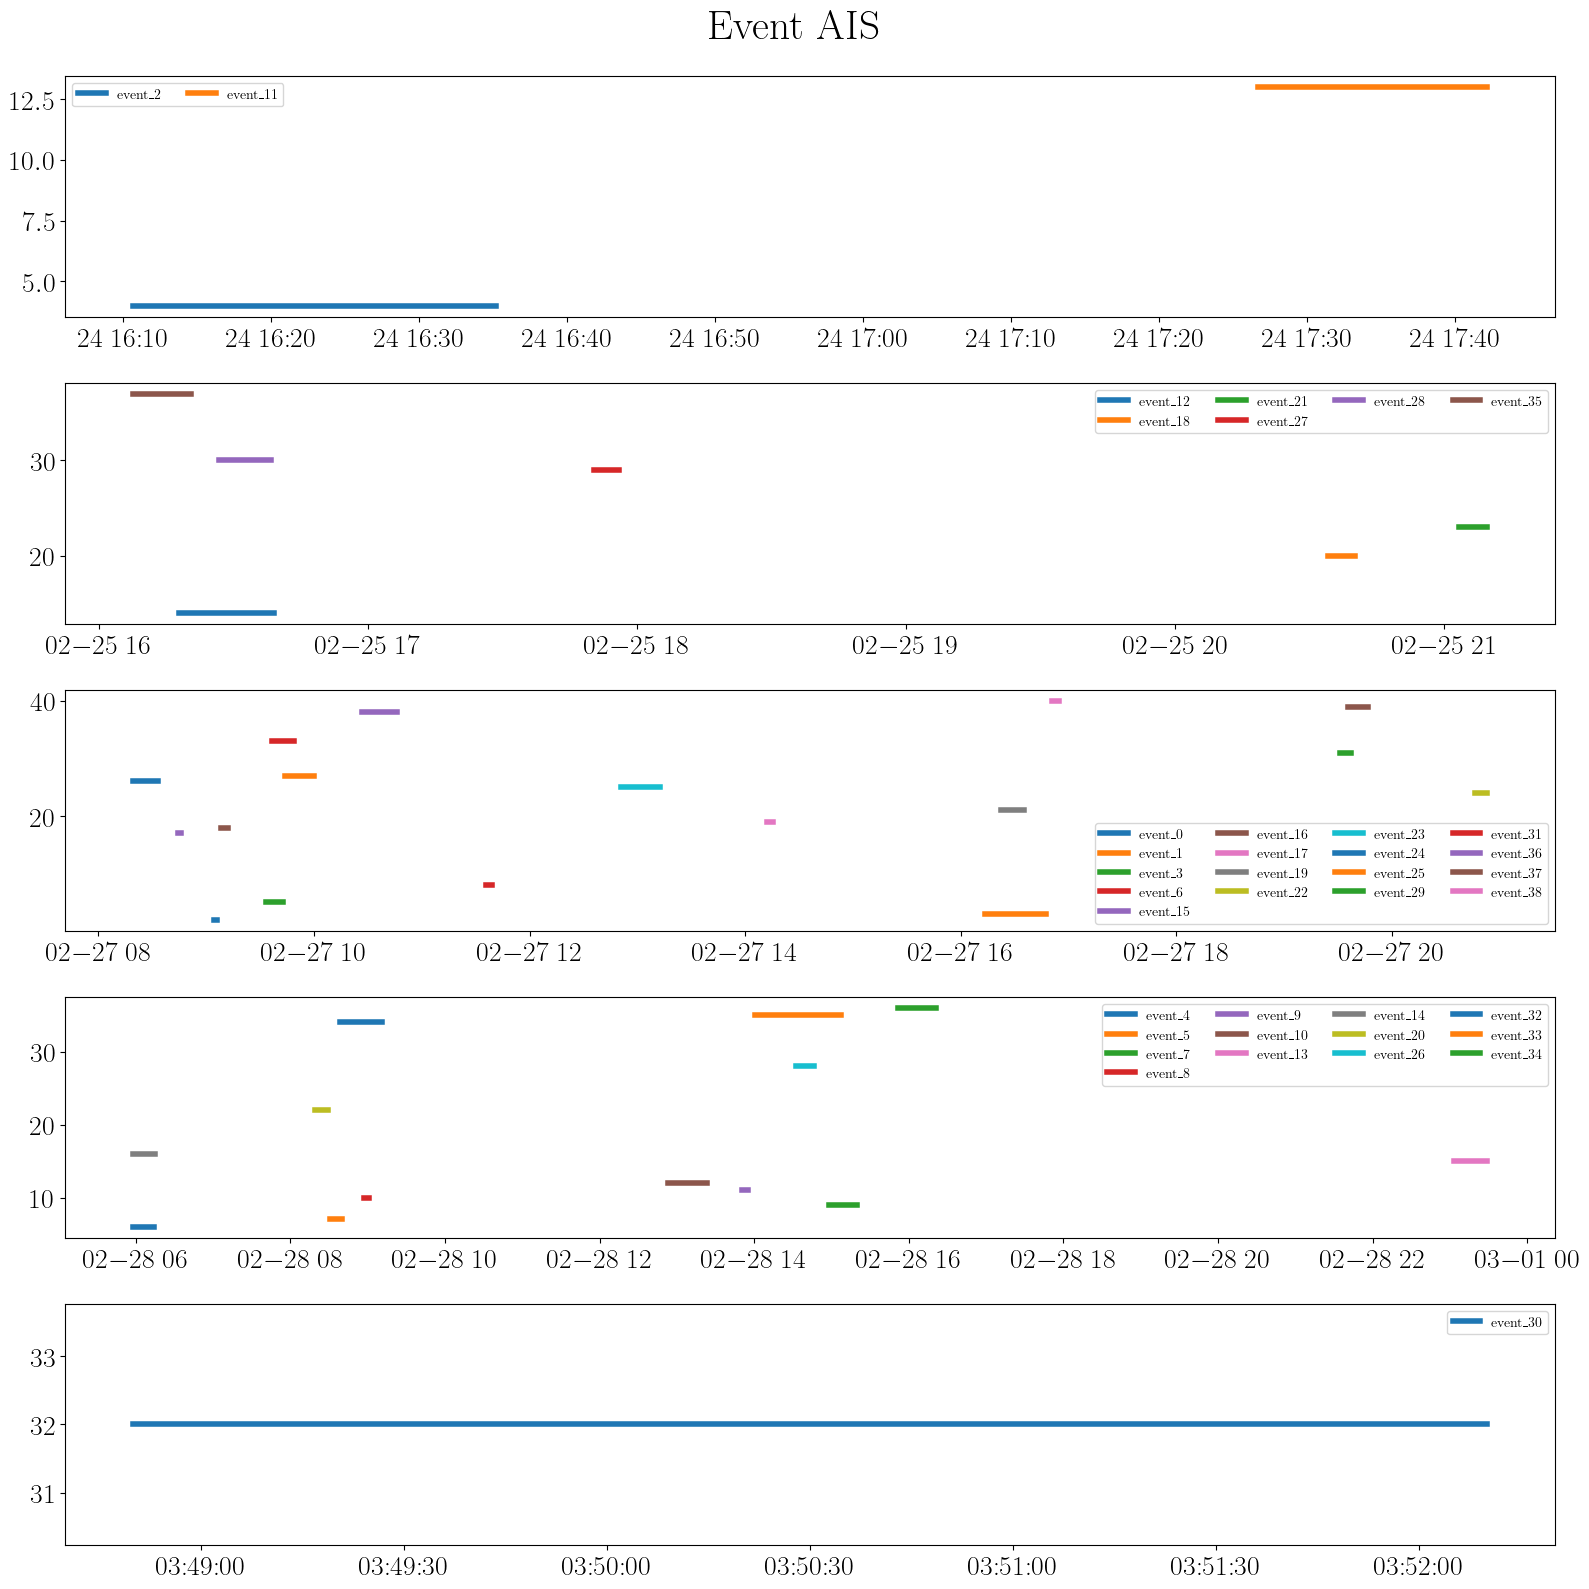

In [12]:
fig, axs = plt.subplots(dt_bounds.size, 1, figsize=(16, 16), sharex=False)

for name, node in portion_event.position.children.items():
    ds_position_event = node.to_dataset()

    # Choose ax
    dt = ds_position_event.datetime
    if dt.min() <= dt_bounds[1]:
        ax = axs[0]
    elif dt.min() >= dt_bounds[1] and  dt.max() <= dt_bounds[2]:
        ax = axs[1]
    elif dt.min() >= dt_bounds[2] and  dt.max() <= dt_bounds[3]:
        ax = axs[2]
    elif dt.min() >= dt_bounds[3] and  dt.max() <= dt_bounds[4]:
        ax = axs[3]
    elif dt.min() >= dt_bounds[4]:
        ax = axs[4]

    ax.plot(
        ds_position_event.datetime,
        np.ones(ds_position_event.datetime.size) + ds_position_event.event_id + 1 ,
        linewidth=4,
        label=name
    )

    # ax.legend(fontsize=10)

fig.suptitle("Event AIS")
for ax in axs.flatten():
    ax.legend(fontsize=10, ncols=4)

fpath = os.path.join(root_img_selection, "event_ais_temporal_coverage.png")
fig.savefig(fpath)

## Visualisation des signaux 

In [16]:
# Plot
single_fig = False
for name, node in portion_event.pressure.children.items():
    if int(name.split("_")[-1]) <= 33:
        print("skip")
        continue
        
    ds_pressure_section = node.to_dataset()
    fig, axs = plot_pressure_section(ds_pressure_section=ds_pressure_section, single_fig=single_fig)
    fig.suptitle(f"Event {ds_pressure_section.event_id}")

    fpath = os.path.join(root_img_signal, f"signal_ais_{name}")
    fig.savefig(fpath)
    plt.close(fig)

skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip
skip


## Spectrogrammes

In [17]:
# Plot
for name, node in portion_event.pressure.children.items():
    print(name)
    ds_pressure_section = node.to_dataset()
    try:
        fig, axs = plot_spectrogram_section(ds_pressure_section, nperseg=2**10, noverlap=2**9, cmap="magma")
    except:
        print(f"Data with different length event : {name}")
        continue
    fig.suptitle(f"Event {ds_pressure_section.event_id}")
    fpath = os.path.join(root_img_spectro, f"spectro_ais_{name}")
    fig.savefig(fpath)
    plt.close(fig)
    # plt.show()

event_0
event_1
event_2
Data with different length event : event_2
event_3
event_4
event_5
event_6
event_7
event_8
event_9
event_10
event_11
event_12
event_13
event_14
event_15
event_16
event_17
event_18
event_19
event_20
event_21
event_22
event_23
event_24
event_25
event_26
event_27
event_28
event_29
event_30
event_31
event_32
event_33
event_34
event_35
event_36
event_37
event_38


In [18]:
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event_ais_mfp.nc"
portion_event_mfp = xr.open_datatree(fpath, auto_complex=True)
portion_event_mfp

<xarray.DataTree>
Group: /
│   Attributes:
│       description:           MFP between a library and events
│       reference_receiver:    obs1
│       computation_settings:  {"compare_centered_gamma": true, "cpsd": {"analysi...
└── Group: /mfp_intersection
    └── Group: /mfp_intersection/sn2
        └── Group: /mfp_intersection/sn2/event_9
                Dimensions:                 (rcv_id: 7, library_datetime: 785,
                                             event_datetime: 609, rcv_id_feature: 5)
                Coordinates:
                  * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
                  * library_datetime        (library_datetime) datetime64[ns] 6kB 2026-02-25T...
                  * event_datetime          (event_datetime) datetime64[ns] 5kB 2026-02-28T23...
                  * rcv_id_feature          (rcv_id_feature) <U4 80B 'obs2' 'obs4' ... 'obs7'
                Data variables: (12/14)
                    rcv_lon                 (rcv_id) float64 56B ...
                    rcv_lat                 (rcv_id) float64 56B ...
                    rcv_immersion           (rcv_id) int16 14B ...
                    library_lon             (library_datetime) float64 6kB ...
                    library_lat             (library_datetime) float64 6kB ...
                    event_lon               (event_datetime) float64 5kB ...
                    ...                      ...
                    d_theta                 (rcv_id_feature, library_datetime, event_datetime) float64 19MB ...
                    d_theta_gamma           (rcv_id_feature, library_datetime, event_datetime) float64 19MB ...
                    d_L2_gamma              (rcv_id_feature, library_datetime, event_datetime) float64 19MB ...
                    d_dcf                   (rcv_id_feature, library_datetime, event_datetime) float64 19MB ...
                    d_theta_gamma_centered  (rcv_id_feature, library_datetime, event_datetime) float64 19MB ...
                    d_L2_gamma_centered     (rcv_id_feature, library_datetime, event_datetime) float64 19MB ...
                Attributes:
                    description:               MFP result for a library section and an event
                    campagne:                  ACOUPLANE
                    section1:                  sn2
                    section2:                  event_9
                    library_acquisition_mode:  active
                    event_acquisition_mode:    passive
                    reference_receiver:        obs1
                    library_rtf_method:        spectral_ratio
                    event_rtf_method:          cs_evd
                    obs_position:              OBS position corrected using LMS inversion.
                    obs_position_filepath:     C:\Users\baptiste.menetrier\Desktop\devPy\phd\...

In [19]:
portion_event_mfp.mfp_intersection.sn1

AttributeError: 'DataTree' object has no attribute 'sn1'

In [ ]:
valid_events = [
    "event_7",
    "event_9",
    "event_15",
    "event_17",
    "event_18",
    "event_24",
    "event_30",
    "event_33",
]
portion_event_mfp_filter = xr.DataTree()
sections = list(portion_event_mfp.mfp_intersection.children)
# print(sections)

for sec_name in sections:
    root_sec = f"mfp_intersection/{sec_name}"
    for e_id_new, event_name in enumerate(valid_events):

        path_mfp_inter = f"{root_sec}/{event_name}"
        portion_event_mfp_filter[path_mfp_inter] = portion_event_mfp[path_mfp_inter].to_dataset()

# portion_event_mfp_filter["event_id"] = np.arange(len(valid_events))
portion_event_mfp_filter.attrs = portion_event_mfp.attrs
portion_event_mfp_filter

# del portion_event
# portion_event = portion_event_filter.copy()
# del portion_event_filter

<xarray.DataTree>
Group: /
│   Attributes:
│       description:         MFP between a library and events
│       reference_receiver:  obs1
└── Group: /mfp_intersection
    ├── Group: /mfp_intersection/sn0
    │   ├── Group: /mfp_intersection/sn0/event_7
    │   │       Dimensions:                 (rcv_id: 7, library_datetime: 787,
    │   │                                    event_datetime: 369, rcv_id_feature: 5)
    │   │       Coordinates:
    │   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
    │   │         * library_datetime        (library_datetime) datetime64[ns] 6kB 2026-02-25T...
    │   │         * event_datetime          (event_datetime) datetime64[ns] 3kB 2026-02-24T17...
    │   │         * rcv_id_feature          (rcv_id_feature) <U4 80B 'obs2' 'obs4' ... 'obs7'
    │   │       Data variables: (12/14)
    │   │           rcv_lon                 (rcv_id) float64 56B ...
    │   │           rcv_lat                 (rcv_id) float64 56B ...
    │   │           rcv_immersion           (rcv_id) int16 14B ...
    │   │           library_lon             (library_datetime) float64 6kB ...
    │   │           library_lat             (library_datetime) float64 6kB ...
    │   │           event_lon               (event_datetime) float64 3kB ...
    │   │           ...                      ...
    │   │           d_theta                 (rcv_id_feature, library_datetime, event_datetime) float64 12MB ...
    │   │           d_theta_gamma           (rcv_id_feature, library_datetime, event_datetime) float64 12MB ...
    │   │           d_L2_gamma              (rcv_id_feature, library_datetime, event_datetime) float64 12MB ...
    │   │           d_dcf                   (rcv_id_feature, library_datetime, event_datetime) float64 12MB ...
    │   │           d_theta_gamma_centered  (rcv_id_feature, library_datetime, event_datetime) float64 12MB ...
    │   │           d_L2_gamma_centered     (rcv_id_feature, library_datetime, event_datetime) float64 12MB ...
    │   │       Attributes:
    │   │           description:               MFP result for a library section and an event
    │   │           campagne:                  ACOUPLANE
    │   │           section1:                  sn0
    │   │           section2:                  event_7
    │   │           library_acquisition_mode:  active
    │   │           event_acquisition_mode:    passive
    │   │           reference_receiver:        obs1
    │   │           obs_position:              OBS position corrected using LMS inversion.
    │   │           obs_position_filepath:     C:\Users\baptiste.menetrier\Desktop\devPy\phd\...
    │   ├── Group: /mfp_intersection/sn0/event_9
    │   │       Dimensions:                 (rcv_id: 7, library_datetime: 787,
    │   │                                    event_datetime: 609, rcv_id_feature: 5)
    │   │       Coordinates:
    │   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
    │   │         * library_datetime        (library_datetime) datetime64[ns] 6kB 2026-02-25T...
    │   │         * event_datetime          (event_datetime) datetime64[ns] 5kB 2026-02-28T23...
    │   │         * rcv_id_feature          (rcv_id_feature) <U4 80B 'obs2' 'obs4' ... 'obs7'
    │   │       Data variables: (12/14)
    │   │           rcv_lon                 (rcv_id) float64 56B ...
    │   │           rcv_lat                 (rcv_id) float64 56B ...
    │   │           rcv_immersion           (rcv_id) int16 14B ...
    │   │           library_lon             (library_datetime) float64 6kB ...
    │   │           library_lat             (library_datetime) float64 6kB ...
    │   │           event_lon               (event_datetime) float64 5kB ...
    │   │           ...                      ...
    │   │           d_theta                 (rcv_id_feature, library_datetime, event_datetime) float64 19MB ...
    │   │           d_theta_gamma           (rcv_id_feature, library_datet

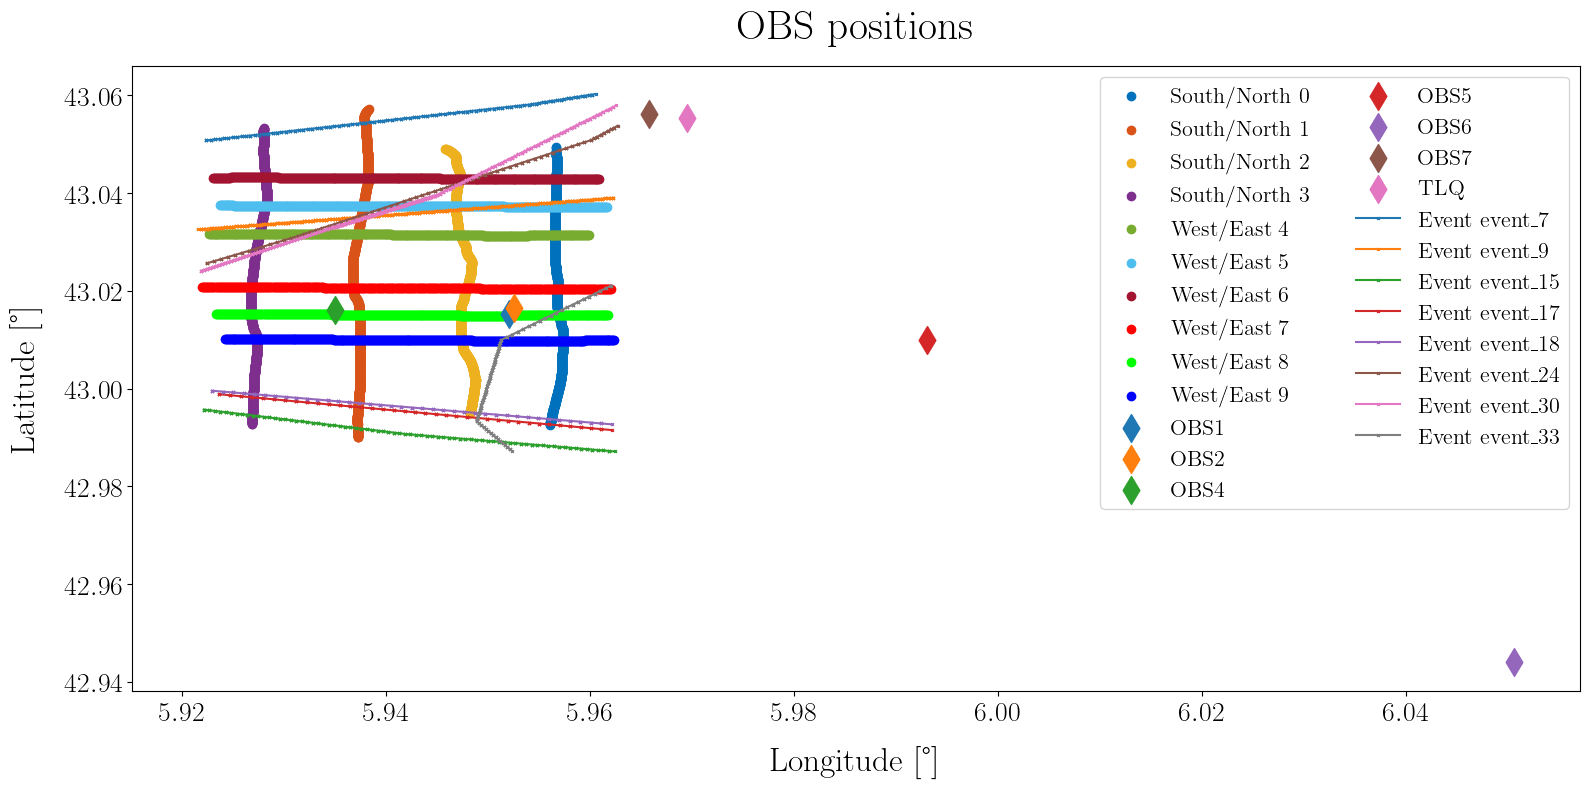

In [ ]:
# Plot
fig, ax = plot_portion_tir_pos(portion_tree=portion)
# ax.add_patch(
#     Rectangle(
#         (portion_event.box_lon_min, portion_event.box_lat_min),
#         portion_event.box_lon_max - portion_event.box_lon_min,
#         portion_event.box_lat_max - portion_event.box_lat_min,
#         fc="none",
#         ec="k",
#         lw=5,
#         label="Selected area",
#     )
# )

for name, node in portion_event_mfp_filter.mfp_intersection["sn1"].children.items():
    ds_intersection = node.to_dataset()
    plt.plot(
        ds_intersection.event_lon,
        ds_intersection.event_lat,
        "-x",
        markersize=2,
        label=f"Event {ds_intersection.section2}",
    )

ax.legend()
legend = ax.get_legend()

if legend is not None:
    handles = legend.legend_handles
    labels = [text.get_text() for text in legend.get_texts()]

    legend.remove()

    ax.legend(
        handles,
        labels,
        loc="upper right",
        fontsize=16,
        ncols=2,
    )